# 08. Computational cost against N

**Question.** How does the time of each model grow with the number of nodes N?

**Data.** Synthetic points, uniform in [0, 1]² (no geospatial overhead).
**Outputs.** `out/benchmark_results.csv` (timings), `out/benchmark_complexity.csv`
(exponents).
**Paper.** Fig. 2 and Sec. 4.3 (the figure itself is drawn by `make_paper_figures.py`
of the paper repository from `out/benchmark_results.csv`).

Three phases per model: inference (analytical calibration for the SP, SVI with
`num_steps = 300` for the BSTPP models), simulation of one pattern, and 2PCF (same code
for all). Sizes N = 100, 250, 500, 1 000, 2 000, 3 repetitions each. 300 SVI steps
measure the scaling, not convergence. The exponent α of t ∝ N^α is fitted per model and
phase.

By default the notebook reads the stored timings (`RUN_BENCHMARK = False`). The full
benchmark takes about 6 minutes, needs BSTPP, JAX and NumPyro, and its timings depend on
the machine.

In [1]:
import sys
import time
import tracemalloc
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
from shapely.geometry import box as _shapely_box

ROOT = Path.cwd().resolve().parent.parent
OUT = ROOT / "out"

RUN_BENCHMARK = False      # True: measure the timings again (about 6 min)

plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 11,
                     "axes.labelsize": 10, "font.size": 9})
SEED = 42
np.random.seed(SEED)

A_GDF = gpd.GeoDataFrame(geometry=[_shapely_box(0.0, 0.0, 1.0, 1.0)])   # BSTPP domain
T_MAX = 365.0
N_SVI_STEPS = 300   # deliberately low, to measure the cost and not the convergence
SVI_LR = 0.01
N_REPEATS = 3       # repetitions per (model, N)
N_VALUES = [100, 250, 500, 1000, 2000]
MODEL_NAMES = ["SP", "LGCP", "Hawkes", "Cox Hawkes"]
print(f"N_SVI_STEPS={N_SVI_STEPS} | N_REPEATS={N_REPEATS} | RUN_BENCHMARK={RUN_BENCHMARK}")

N_SVI_STEPS=300 | N_REPEATS=3 | RUN_BENCHMARK=False


In [2]:
# ── Synthetic data, simplified SP and 2PCF in [0, 1]^2 ─────────────────────────


def make_synthetic_data(N, seed=SEED):
    """N uniform points in [0, 1]^2, sorted by T ~ U(0, T_MAX)."""
    rng = np.random.default_rng(seed)
    xy = rng.uniform(0, 1, (N, 2))
    T = np.sort(rng.uniform(0, T_MAX, N))
    return pd.DataFrame({"X": xy[:, 0], "Y": xy[:, 1], "T": T})


def sp_generate(N, eta=4, L=5, gamma=0.8, seed=SEED):
    """N points of an SP fractal in [0, 1]^2, without geospatial machinery.

    lambda = eta^(1/(2-gamma)) and the root radius is R = 0.5.
    """
    rng = np.random.default_rng(seed)
    lamb = eta ** (1.0 / (2.0 - gamma))
    R = 0.5
    positions = rng.uniform(0.1, 0.9, (1, 2))      # central seed
    for lvl in range(L):
        r_lvl = R / (lamb ** lvl)
        new_pts = []
        for cx, cy in positions:
            r = r_lvl * rng.uniform(0, 1, eta)
            theta = rng.uniform(0, 2 * np.pi, eta)
            new_pts.append(np.column_stack([cx + r * np.cos(theta),
                                            cy + r * np.sin(theta)]))
        positions = np.vstack(new_pts)
    # clip, then subsample or pad with uniform points to reach N
    positions = np.clip(positions, 0, 1)
    if len(positions) >= N:
        return positions[rng.choice(len(positions), N, replace=False)]
    extra = rng.uniform(0, 1, (N - len(positions), 2))
    return np.vstack([positions, extra])


def compute_2pcf(xy, n_random=2000, n_bins=18):
    """Landy-Szalay 2PCF in [0, 1]^2 (one random catalogue)."""
    DD_raw = cdist(xy, xy)
    DD_raw = np.triu(DD_raw, k=1).ravel()
    DD_raw = DD_raw[DD_raw > 0]
    if len(DD_raw) == 0:
        return None, None
    nn, _ = cKDTree(xy).query(xy, k=2)
    rmin = max(np.mean(nn[:, 1]) * 0.5, 1e-5)
    rmax = np.max(DD_raw) * 0.55
    r_edges = np.logspace(np.log10(rmin), np.log10(rmax), n_bins + 1)
    r_centers = np.sqrt(r_edges[:-1] * r_edges[1:])
    DD_norm = np.histogram(DD_raw, bins=r_edges)[0] / max(len(DD_raw), 1)
    rand_xy = np.random.default_rng(99).uniform(0, 1, (n_random, 2))
    DR_raw = cdist(xy, rand_xy).ravel()
    DR_norm = np.histogram(DR_raw, bins=r_edges)[0] / max(len(DR_raw), 1)
    RR_raw = np.triu(cdist(rand_xy, rand_xy), k=1).ravel()
    RR_raw = RR_raw[RR_raw > 0]
    RR_norm = np.histogram(RR_raw, bins=r_edges)[0] / max(len(RR_raw), 1)
    with np.errstate(divide="ignore", invalid="ignore"):
        xi = np.where(RR_norm > 0, (DD_norm - 2 * DR_norm + RR_norm) / RR_norm, np.nan)
    return r_centers, xi

In [3]:
# ── Timing functions ───────────────────────────────────────────────────────────


def timed(fn):
    """Run fn() and return (result, duration in s, peak memory in MB)."""
    tracemalloc.start()
    t0 = time.perf_counter()
    res = fn()
    dt = time.perf_counter() - t0
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return res, dt, peak / 1e6


def benchmark_sp(N, seed=SEED):
    """SP calibration and generation. Returns a dict of timings."""
    # calibration = lambda and L from gamma, O(1) and analytical
    _, t_calib, mem_calib = timed(lambda: (
        4 ** (1.0 / (2.0 - 0.8)),
        max(1, round(np.log(N) / np.log(4)))))
    _, t_sim, mem_sim = timed(lambda: sp_generate(N, seed=seed))
    xy_sp = sp_generate(N, seed=seed)
    _, t_2pcf, mem_2pcf = timed(lambda: compute_2pcf(xy_sp))
    return {"t_inference": t_calib, "t_simulation": t_sim, "t_2pcf": t_2pcf,
            "t_total": t_calib + t_sim + t_2pcf,
            "mem_peak_MB": max(mem_calib, mem_sim, mem_2pcf), "status": "OK"}


def benchmark_bstpp(model_class, N, cox_background=False, seed=SEED):
    """SVI and simulation for one BSTPP model. Returns a dict of timings."""
    from bstpp.main import LGCP_Model, Hawkes_Model
    import numpyro.distributions as dist

    data_df = make_synthetic_data(N, seed=seed)
    common_priors = dict(a_0=dist.Normal(0, 5))
    hawkes_priors = dict(alpha=dist.Beta(2, 5), beta=dist.HalfNormal(2.0),
                         sigmax_2=dist.HalfNormal(0.25))
    tracemalloc.start()
    t0 = time.perf_counter()
    try:
        if model_class == "LGCP":
            model = LGCP_Model(data_df, A_GDF, T_MAX, **common_priors)
        else:
            model = Hawkes_Model(data_df, A_GDF, T_MAX, cox_background=cox_background,
                                 **common_priors, **hawkes_priors)
        model.run_svi(lr=SVI_LR, num_steps=N_SVI_STEPS, plot_loss=False)
        t_infer = time.perf_counter() - t0
        _, mem_infer = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        sim_result, t_sim, mem_sim = timed(lambda: model.simulate())
        xy_sim = sim_result[["X", "Y"]].values
        n_sim = len(xy_sim)
        xy_2pcf = xy_sim[:min(n_sim, 2000)]           # capped at 2000 points
        _, t_2pcf, mem_2pcf = timed(lambda: compute_2pcf(xy_2pcf))
        return {"t_inference": t_infer, "t_simulation": t_sim, "t_2pcf": t_2pcf,
                "t_total": t_infer + t_sim + t_2pcf,
                "mem_peak_MB": max(mem_infer / 1e6, mem_sim, mem_2pcf),
                "n_simulated": n_sim, "status": "OK"}
    except Exception as e:
        tracemalloc.stop()
        return {"status": f"FAILED: {e}", "t_inference": np.nan,
                "t_simulation": np.nan, "t_2pcf": np.nan,
                "t_total": np.nan, "mem_peak_MB": np.nan}

In [4]:
# ── Sweep over N, or reading of the stored timings ─────────────────────────────

if RUN_BENCHMARK:
    import jax
    import numpyro
    print(f"JAX {jax.__version__} | NumPyro {numpyro.__version__}")
    BENCH = {
        "SP": lambda N, seed: benchmark_sp(N, seed),
        "LGCP": lambda N, seed: benchmark_bstpp("LGCP", N, seed=seed),
        "Hawkes": lambda N, seed: benchmark_bstpp("Hawkes", N, cox_background=False,
                                                  seed=seed),
        "Cox Hawkes": lambda N, seed: benchmark_bstpp("Hawkes", N, cox_background=True,
                                                      seed=seed),
    }
    all_rows = []
    for N in N_VALUES:
        print(f"\n{'=' * 60}\n  N = {N}\n{'=' * 60}")
        for model_name, bench_fn in BENCH.items():
            times = []
            for rep in range(N_REPEATS):
                res = bench_fn(N, seed=SEED + rep)
                times.append(res)
                if "FAILED" in str(res.get("status", "OK")):
                    print(f"  {model_name} rep{rep + 1}: {res['status']}")
                    break
                n_sim_str = (f" | n_sim={res['n_simulated']}" if "n_simulated" in res
                             else "")
                print(f"  {model_name:12s} rep{rep + 1}  t_inf={res['t_inference']:.2f}s  "
                      f"t_sim={res['t_simulation']:.3f}s  t_2pcf={res['t_2pcf']:.3f}s  "
                      f"mem={res['mem_peak_MB']:.1f}MB{n_sim_str}")
            valid = [t for t in times if not np.isnan(t.get("t_total", np.nan))]
            row = {"N": N, "Model": model_name}
            for k in ("t_inference", "t_simulation", "t_2pcf", "t_total"):
                row[f"{k}_mean"] = np.mean([t[k] for t in valid]) if valid else np.nan
                row[f"{k}_std"] = np.std([t[k] for t in valid]) if valid else np.nan
            row["mem_peak_MB"] = (np.mean([t["mem_peak_MB"] for t in valid])
                                  if valid else np.nan)
            row["n_reps"] = len(valid)
            all_rows.append(row)
    df_bench = pd.DataFrame(all_rows)
    df_bench.to_csv(OUT / "benchmark_results.csv", index=False)
    print("\nbenchmark done, written to out/benchmark_results.csv")
else:
    df_bench = pd.read_csv(OUT / "benchmark_results.csv")
    print("timings read from out/benchmark_results.csv")

timings read from out/benchmark_results.csv


In [5]:
cols_show = ["N", "Model", "t_inference_mean", "t_simulation_mean", "t_2pcf_mean",
             "t_total_mean", "mem_peak_MB"]
fmt = {c: (lambda x: f"{x:.3f}") for c in cols_show[2:6]}
fmt["mem_peak_MB"] = lambda x: f"{x:.1f}"
print("times in seconds | memory in MB (tracemalloc peak)")
print(df_bench[cols_show].to_string(index=False, formatters=fmt))

times in seconds | memory in MB (tracemalloc peak)
   N      Model t_inference_mean t_simulation_mean t_2pcf_mean t_total_mean mem_peak_MB
 100         SP            0.000             0.011       0.060        0.072        69.7
 100       LGCP            6.188             0.203       0.057        6.449        69.5
 100     Hawkes            5.243             0.028       0.059        5.330        69.5
 100 Cox Hawkes            3.872             0.159       0.052        4.083        69.1
 250         SP            0.000             0.013       0.052        0.065        72.3
 250       LGCP            1.679             0.228       0.054        1.960        71.8
 250     Hawkes            2.755             0.015       0.051        2.820        72.2
 250 Cox Hawkes            2.476             0.187       0.048        2.711        70.4
 500         SP            0.000             0.016       0.077        0.093        77.0
 500       LGCP            1.932             0.330       0.055       

In [6]:
# ── Fit of the complexity, t ~ N^alpha ─────────────────────────────────────────


def fit_complexity(ns, ts):
    """Fit t = a N^alpha on the valid (N, t) points, in log-log."""
    mask = np.isfinite(ts) & (ts > 0) & (ns > 0)
    if mask.sum() < 2:
        return np.nan, np.nan
    alpha, log_a = np.polyfit(np.log10(ns[mask]), np.log10(ts[mask]), 1)
    return alpha, 10 ** log_a


PHASES = [("inference", "t_inference_mean"), ("simulation", "t_simulation_mean"),
          ("2PCF", "t_2pcf_mean"), ("total", "t_total_mean")]
print(f"{'Model':<14} {'Phase':<14} {'exponent α':<12}")
print("-" * 40)
complexity_rows = []
for model_name in MODEL_NAMES:
    sub = df_bench[df_bench["Model"] == model_name].sort_values("N")
    ns = sub["N"].values.astype(float)
    for phase, col in PHASES:
        alpha, a = fit_complexity(ns, sub[col].values.astype(float))
        complexity_rows.append({"Model": model_name, "Phase": phase,
                                "alpha": alpha, "prefactor": a})
        alpha_str = f"{alpha:.2f}" if np.isfinite(alpha) else "N/A"
        print(f"{model_name:<14} {phase:<14} {alpha_str:<12}")
df_complexity = pd.DataFrame(complexity_rows)
df_complexity.to_csv(OUT / "benchmark_complexity.csv", index=False)

Model          Phase          exponent α  
----------------------------------------
SP             inference      -0.12       
SP             simulation     0.01        
SP             2PCF           0.18        
SP             total          0.16        
LGCP           inference      -0.46       
LGCP           simulation     0.39        
LGCP           2PCF           0.07        
LGCP           total          -0.34       
Hawkes         inference      0.59        
Hawkes         simulation     -0.13       
Hawkes         2PCF           -0.11       
Hawkes         total          0.59        
Cox Hawkes     inference      0.69        
Cox Hawkes     simulation     0.37        
Cox Hawkes     2PCF           0.04        
Cox Hawkes     total          0.68        


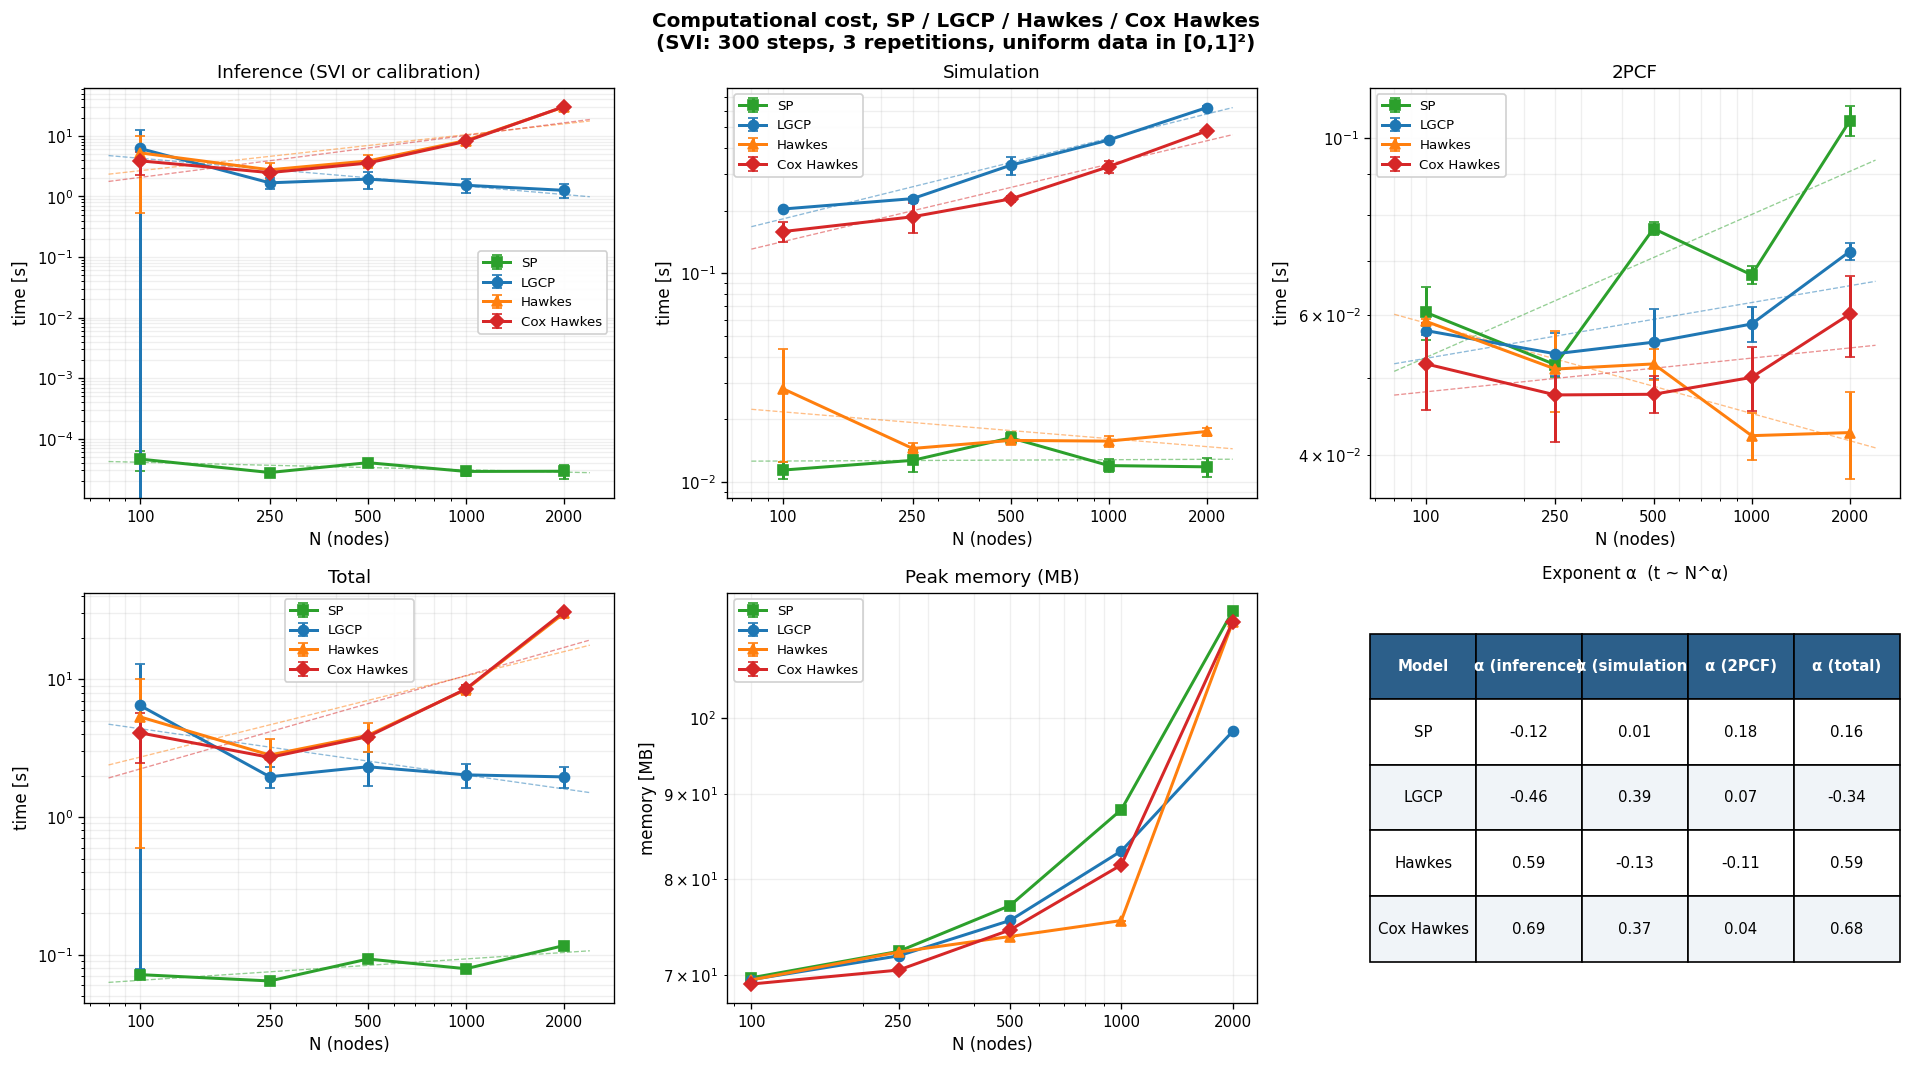

In [7]:
# ── Figure ─────────────────────────────────────────────────────────────────────

COLORS = {"SP": "#2ca02c", "LGCP": "#1f77b4", "Hawkes": "#ff7f0e",
          "Cox Hawkes": "#d62728"}
MARKERS = {"SP": "s", "LGCP": "o", "Hawkes": "^", "Cox Hawkes": "D"}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Computational cost, SP / LGCP / Hawkes / Cox Hawkes\n"
             f"(SVI: {N_SVI_STEPS} steps, {N_REPEATS} repetitions, uniform data in [0,1]²)",
             fontsize=12, fontweight="bold")
panels = [("Inference (SVI or calibration)", "t_inference_mean", "t_inference_std",
           "inference"),
          ("Simulation", "t_simulation_mean", "t_simulation_std", "simulation"),
          ("2PCF", "t_2pcf_mean", "t_2pcf_std", "2PCF"),
          ("Total", "t_total_mean", "t_total_std", "total"),
          ("Peak memory (MB)", "mem_peak_MB", None, None)]
N_arr = np.array(N_VALUES, dtype=float)
N_fit = np.logspace(np.log10(N_arr[0] * 0.8), np.log10(N_arr[-1] * 1.2), 100)

for ax, (title, col_mean, col_std, phase) in zip(axes.flat[:5], panels):
    for model_name in MODEL_NAMES:
        sub = df_bench[df_bench["Model"] == model_name].sort_values("N")
        ns = sub["N"].values.astype(float)
        ts = sub[col_mean].values.astype(float)
        err = sub[col_std].values.astype(float) if col_std else np.zeros_like(ts)
        ax.errorbar(ns, ts, yerr=err, color=COLORS[model_name],
                    marker=MARKERS[model_name], label=model_name, lw=1.8, ms=6,
                    capsize=3)
        if phase is not None:                       # fitted power law
            row = df_complexity[(df_complexity["Model"] == model_name)
                                & (df_complexity["Phase"] == phase)]
            if not row.empty and np.isfinite(row.iloc[0]["alpha"]):
                ax.plot(N_fit, row.iloc[0]["prefactor"] * N_fit ** row.iloc[0]["alpha"],
                        color=COLORS[model_name], lw=0.8, ls="--", alpha=0.5)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("N (nodes)")
    ax.set_ylabel("time [s]" if col_mean != "mem_peak_MB" else "memory [MB]")
    ax.set_title(title)
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.set_xticks(N_VALUES)
    ax.legend(fontsize=8, framealpha=0.9)
    ax.grid(True, which="both", alpha=0.2)

ax_tab = axes.flat[5]
ax_tab.axis("off")
table_data = []
for model_name in MODEL_NAMES:
    row_vals = [model_name]
    for ph, _ in PHASES:
        r = df_complexity[(df_complexity["Model"] == model_name)
                          & (df_complexity["Phase"] == ph)]
        row_vals.append(f"{r.iloc[0]['alpha']:.2f}"
                        if not r.empty and np.isfinite(r.iloc[0]["alpha"]) else "N/A")
    table_data.append(row_vals)
table = ax_tab.table(cellText=table_data,
                     colLabels=["Model"] + [f"α ({p})" for p, _ in PHASES],
                     cellLoc="center", loc="center", bbox=[0, 0.1, 1.0, 0.8])
table.auto_set_font_size(False)
table.set_fontsize(9)
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor("#2c5f8a")
        cell.set_text_props(color="white", fontweight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#f0f4f8")
ax_tab.set_title("Exponent α  (t ~ N^α)", fontsize=10, pad=8)

plt.tight_layout()
plt.savefig(OUT / "benchmark_complexity.pdf", bbox_inches="tight", dpi=150)
plt.show()

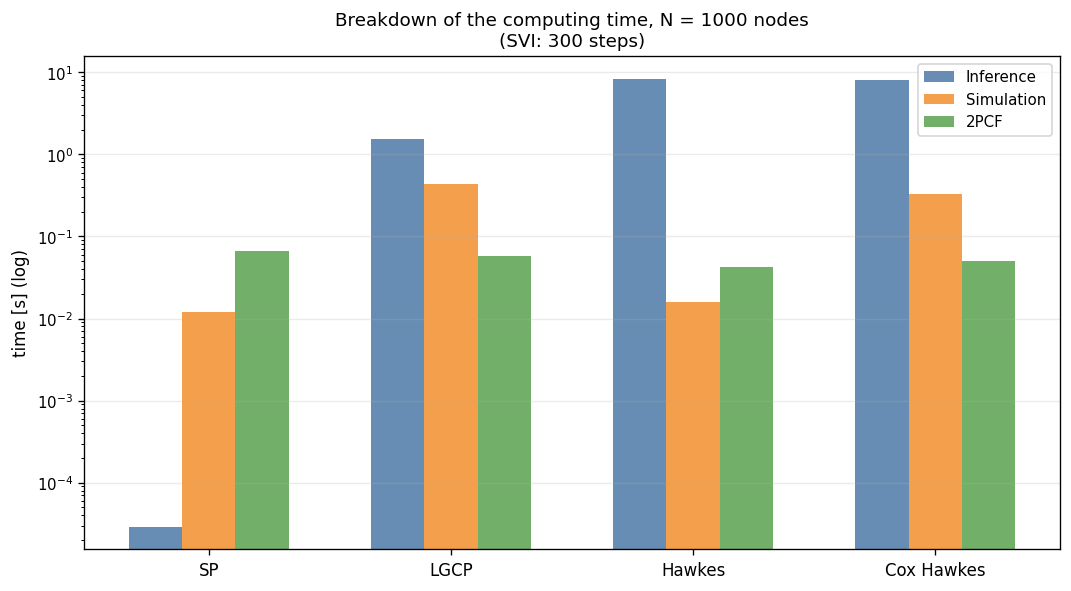

In [8]:
# ── Breakdown by phase at fixed N ──────────────────────────────────────────────

N_HIGHLIGHT = 1000
sub = df_bench[df_bench["N"] == N_HIGHLIGHT].set_index("Model")
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(MODEL_NAMES))
width = 0.22
for i, (label, col, color) in enumerate([("Inference", "t_inference_mean", "#4e79a7"),
                                         ("Simulation", "t_simulation_mean", "#f28e2b"),
                                         ("2PCF", "t_2pcf_mean", "#59a14f")]):
    vals = [sub.loc[m, col] if m in sub.index else np.nan for m in MODEL_NAMES]
    ax.bar(x + (i - 1) * width, vals, width, label=label, color=color, alpha=0.85)
ax.set_yscale("log")
ax.set_xticks(x); ax.set_xticklabels(MODEL_NAMES, fontsize=10)
ax.set_ylabel("time [s] (log)")
ax.set_title(f"Breakdown of the computing time, N = {N_HIGHLIGHT} nodes\n"
             f"(SVI: {N_SVI_STEPS} steps)", fontsize=11)
ax.legend(fontsize=9); ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "benchmark_breakdown.pdf", bbox_inches="tight", dpi=150)
plt.show()

In [9]:
# ── Speed-up relative to LGCP (total time) ─────────────────────────────────────

speed = {}
for N in N_VALUES:
    sub = df_bench[df_bench["N"] == N].set_index("Model")
    t_ref = sub.loc["LGCP", "t_total_mean"]
    speed[N] = {m: t_ref / sub.loc[m, "t_total_mean"] for m in MODEL_NAMES}
print("speed-up relative to LGCP (total time)")
print(pd.DataFrame(speed).T.round(1).to_string())

print("\n=== Summary ===")
for model_name in MODEL_NAMES:
    row = df_complexity[(df_complexity["Model"] == model_name)
                        & (df_complexity["Phase"] == "total")]
    print(f"  {model_name:<14} total time ~ O(N^{row.iloc[0]['alpha']:.2f})")
print("written: out/benchmark_complexity.csv")

speed-up relative to LGCP (total time)
        SP  LGCP  Hawkes  Cox Hawkes
100   89.7   1.0     1.2         1.6
250   30.3   1.0     0.7         0.7
500   24.8   1.0     0.6         0.6
1000  25.5   1.0     0.2         0.2
2000  16.7   1.0     0.1         0.1

=== Summary ===
  SP             total time ~ O(N^0.16)
  LGCP           total time ~ O(N^-0.34)
  Hawkes         total time ~ O(N^0.59)
  Cox Hawkes     total time ~ O(N^0.68)
written: out/benchmark_complexity.csv


## Results

| N = 2 000 | inference (s) | total (s) |
|---|---|---|
| SP | 3·10⁻⁵ | 0.12 |
| LGCP | 1.26 | 1.96 |
| Hawkes | 30.0 | 30.1 |
| Cox-Hawkes | 30.4 | 30.9 |

- At N = 2 000 the SP calibration is about 4·10⁴ times faster than the LGCP fit and
  10⁶ times faster than the Hawkes fits. In total time the SP is 17 times faster than
  the LGCP and about 260 times faster than the two Hawkes processes.
- The total time of the SP is dominated by the 2PCF (0.06 to 0.1 s).
- Exponents of the total time: SP 0.16, Hawkes 0.59, Cox-Hawkes 0.68. The LGCP time
  decreases from N = 100 to 250 (6.4 s to 2.0 s, most probably compilation at the first
  call) and is then flat, set by the fixed number of SVI steps, hence a negative
  exponent (−0.34). These exponents only describe this range of N.